# Лабораторная работа 9. Энкодерные модели, эмбеддинги и retrieval (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 3:** предобучение и представления

**Цель.** Разобрать двунаправленные модели (MLM) и контрастивное обучение представлений, на котором строятся поиск и RAG.

**Что нужно сдать:**
1. Маленький BERT, предобученный с MLM (маскирование 80/10/10), и каузальную модель того же размера; сравнение linear probing на классификации.
2. Bi-encoder, обученный InfoNCE с in-batch и hard negatives.
3. Эксперимент с температурой и размером батча; метрики alignment и uniformity.
4. Поиск с индексом и cross-encoder реранкингом; Recall@k, MRR, nDCG@10.
5. Минимальный RAG-пайплайн с предобученной LLM и анализ, когда извлечённый контекст помогает.

**Данные.** AG News: заголовок, краткое описание, одна из четырёх тем (World, Sports, Business, Sci/Tech). Пары «заголовок → описание» служат задачей поиска.

**Теория. InfoNCE.** Для запроса \(q\), положительного документа \(d^+\) и \(K-1\) негативов:
\[
$$\mathcal{L} = -\log\frac{\exp(s(q,d^+)/\tau)}{\sum_{j=1}^{K}\exp(s(q,d_j)/\tau)},\qquad I(q; d) \ge \log K - \mathcal{L}.$$
\]
**Alignment и uniformity** (Wang & Isola, 2020) для нормированных эмбеддингов:
\[
$$\ell_{align} = \mathbb{E}_{(x,y)\sim p_{pos}}\|f(x)-f(y)\|^2,\qquad$$
$$\ell_{unif} = \log\mathbb{E}_{x,y\sim p}\, e^{-2\|f(x)-f(y)\|^2}.$$
\]

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.12.0.dev20260408+cu128, device=cuda, FAST_DEV_RUN=True


## 0. Данные и токенизация

In [2]:
import re, csv
from collections import Counter

def load_ag(split):
    path = download(f"https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/{split}.csv", f"ag_{split}.csv")
    rows = list(csv.reader(open(path, encoding="utf-8")))
    return [(int(r[0]) - 1, r[1].replace("\\", " "), r[2].replace("\\", " ")) for r in rows]

ag_train, ag_test = load_ag("train"), load_ag("test")
random.Random(0).shuffle(ag_train); random.Random(1).shuffle(ag_test)
N_PRE, N_PROBE, N_TEST = (20000, 2000, 1000) if FAST_DEV_RUN else (120000, 10000, 7600)
pretrain, probe_train, test = ag_train[:N_PRE], ag_train[N_PRE:N_PRE + N_PROBE], ag_test[:N_TEST]
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]

TOKEN_RE = re.compile(r"\w+|[^\w\s]")
def words(s): return TOKEN_RE.findall(s.lower())
SPECIALS = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
cnt = Counter(w for _, t, d in pretrain for w in words(t + " " + d))
itos = SPECIALS + [w for w, _ in cnt.most_common(8000 if FAST_DEV_RUN else 30000)]
stoi = {w: i for i, w in enumerate(itos)}; PAD, UNK, CLS, SEP, MASK = range(5); VOCAB = len(itos)
MAX_LEN = 48

def encode(text, max_len=MAX_LEN, cls=True):
    ids = ([CLS] if cls else []) + [stoi.get(w, UNK) for w in words(text)]
    return ids[:max_len]

def pad_batch(seqs):
    T = max(len(s) for s in seqs); x = torch.full((len(seqs), T), PAD)
    for i, s in enumerate(seqs): x[i, :len(s)] = torch.tensor(s)
    return x.to(DEVICE)
print(f"словарь {VOCAB}, пример: {encode(pretrain[0][1])[:15]}")

словарь 8005, пример: [2, 1, 75, 5, 143, 5, 65, 14, 1]


## 1. Энкодер и каузальная модель одинакового размера

Одна архитектура (Pre-RMSNorm, SwiGLU, обучаемые позиции) с флагом `causal`. Паддинг маскируется в attention.

In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d): super().__init__(); self.w = nn.Parameter(torch.ones(d))
    def forward(self, x): return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + 1e-6) * self.w

class Layer(nn.Module):
    def __init__(self, d, h):
        super().__init__(); self.h = h
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d)
        self.qkv, self.o = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False)
        hid = int(8 * d / 3); self.w1, self.w3, self.w2 = nn.Linear(d, hid, bias=False), nn.Linear(d, hid, bias=False), nn.Linear(hid, d, bias=False)
    def forward(self, x, pad_mask, causal):
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in self.qkv(self.n1(x)).split(C, 2))
        allowed = ~pad_mask[:, None, None, :]                                      # (B,1,1,T)
        if causal: allowed = allowed & torch.ones(T, T, dtype=torch.bool, device=x.device).tril()
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed)
        x = x + self.o(y.transpose(1, 2).reshape(B, T, C))
        z = self.n2(x); return x + self.w2(F.silu(self.w1(z)) * self.w3(z))

class Encoder(nn.Module):
    def __init__(self, vocab=VOCAB, d=128, n_layer=2 if FAST_DEV_RUN else 4, n_head=4, max_len=2 * MAX_LEN + 2, causal=False):
        super().__init__(); self.causal = causal
        self.emb = nn.Embedding(vocab, d); self.pos = nn.Parameter(torch.randn(max_len, d) * 0.02)
        self.layers = nn.ModuleList([Layer(d, n_head) for _ in range(n_layer)]); self.norm = RMSNorm(d)
        self.lm_head = nn.Linear(d, vocab, bias=False); self.lm_head.weight = self.emb.weight
        for mod in self.modules():                       # без этой инициализации (N(0,1) у эмбеддингов) обучение почти не идёт
            if isinstance(mod, (nn.Linear, nn.Embedding)): nn.init.normal_(mod.weight, std=0.02)
    def forward(self, x):
        pad = x == PAD; h = self.emb(x) + self.pos[: x.size(1)]
        for l in self.layers: h = l(h, pad, self.causal)
        return self.norm(h)
    def pool(self, x, how="mean"):
        h = self(x); m = (x != PAD).float()[..., None]
        if how == "mean": return (h * m).sum(1) / m.sum(1)
        if how == "cls": return h[:, 0]
        last = (x != PAD).sum(1) - 1; return h[torch.arange(len(x)), last]

## 2. Предобучение: MLM и causal LM

**MLM:** выберите 15% токенов (не специальных); из них 80% заменить на `[MASK]`, 10% — на случайный токен, 10% оставить. Loss — только на выбранных позициях.

In [4]:
def mask_tokens(x, p=0.15):
    xm = x.clone()
    prob = torch.full(x.shape, p, device=x.device)
    prob[x < len(SPECIALS)] = 0.0 

    sel = torch.bernoulli(prob).bool()

    labels = torch.full_like(x, -100)
    labels[sel] = x[sel]

    r = torch.rand(x.shape, device=x.device)

    mask_80     = sel & (r < 0.8)
    mask_10_rnd = sel & (r >= 0.8) & (r < 0.9)

    xm[mask_80] = MASK
    rand_tok = torch.randint(len(SPECIALS), VOCAB, x.shape, device=x.device)
    xm[mask_10_rnd] = rand_tok[mask_10_rnd]
    
    return xm, labels

x = pad_batch([encode(t + " " + d) for _, t, d in pretrain[:256]]); xm, lab = mask_tokens(x)
sel = lab != -100
print(f"доля выбранных: {sel.float().sum() / (x >= len(SPECIALS)).float().sum():.3f}; из них [MASK]: {(xm[sel] == MASK).float().mean():.2f}, без изменений: {(xm[sel] == x[sel]).float().mean():.2f}")

доля выбранных: 0.149; из них [MASK]: 0.83, без изменений: 0.10


In [ ]:
PRE_STEPS = 600 if FAST_DEV_RUN else 10000
pre_texts = [encode(t + " " + d) for _, t, d in pretrain]

def pretrain_model(causal, steps=PRE_STEPS, B=64, lr=3e-3, warmup=50):
    set_seed(); 
    m = Encoder(causal=causal).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01); 
    hist = []
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * s / steps)))
    
    for s in range(steps):
        x = pad_batch(random.sample(pre_texts, B))
        # (MLM — mask_tokens и loss по меткам; causal — сдвиг на один токен, паддинг игнорировать)
        if not causal:
            xm, labels = mask_tokens(x)
            logits = m.lm_head(m(xm))
            loss = F.cross_entropy(logits.view(-1, VOCAB), labels.view(-1), ignore_index=-100)
        else:
            logits = m.lm_head(m(x))
            shift_logits = logits[:, :-1].contiguous()
            shift_labels = x[:, 1:].clone()
            shift_labels[shift_labels == PAD] = -100
            loss = F.cross_entropy(shift_logits.view(-1, VOCAB),
                                shift_labels.reshape(-1), ignore_index=-100)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step(); sched.step()
        if s % 100 == 0: hist.append(loss.item())
    return m, hist

t0 = time.time(); mlm, h1 = pretrain_model(False); clm, h2 = pretrain_model(True)
print(f"{time.time() - t0:.0f} c; MLM loss {h1[-1]:.3f}, CLM loss {h2[-1]:.3f}")

12 c; MLM loss 5.690, CLM loss 5.178


## 3. Linear probing

Заморозьте модели, получите признаки (mean pooling; для каузальной модели также последний токен) и обучите логистическую регрессию на `probe_train`. Сравните с моделью со случайной инициализацией и с TF-IDF.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

@torch.no_grad()
def features(m, docs, how="mean", B=256):
    m.eval(); out = []
    for i in range(0, len(docs), B):
        out.append(m.pool(pad_batch([encode(t + " " + d) for _, t, d in docs[i:i + B]]), how).cpu())
    m.train(); 
    return torch.cat(out).numpy()

def probe(Xtr, Xte):
    clf = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr, [y for y, _, _ in probe_train])
    return clf.score(Xte, [y for y, _, _ in test])

# (точность для MLM(mean), CLM(mean), CLM(last), random(mean), TF-IDF)
results_probe = {}

Xtr = features(mlm,  probe_train, "mean"); 
Xte = features(mlm,  test, "mean")
results_probe["MLM (mean)"] = probe(Xtr, Xte)

Xtr = features(clm,  probe_train, "mean"); 
Xte = features(clm,  test, "mean")
results_probe["CLM (mean)"] = probe(Xtr, Xte)

Xtr = features(clm,  probe_train, "last"); 
Xte = features(clm,  test, "last")
results_probe["CLM (last)"] = probe(Xtr, Xte)

set_seed(); rnd = Encoder(causal=False).to(DEVICE)
Xtr = features(rnd, probe_train, "mean"); 
Xte = features(rnd, test, "mean")
results_probe["Random (mean)"] = probe(Xtr, Xte)

tfidf_probe = TfidfVectorizer(min_df=2, max_features=50000).fit(
    [t + " " + d for _, t, d in probe_train])
Xtr = tfidf_probe.transform([t + " " + d for _, t, d in probe_train])
Xte = tfidf_probe.transform([t + " " + d for _, t, d in test])
clf = LogisticRegression(max_iter=2000).fit(Xtr, [y for y, _, _ in probe_train])
results_probe["TF-IDF"] = clf.score(Xte, [y for y, _, _ in test])

pd.DataFrame([results_probe]).T.round(3)

,0
MLM (mean),0.766
CLM (mean),0.700
CLM (last),0.522
Random (mean),0.501
TF-IDF,0.862


## 4. Bi-encoder с InfoNCE

Запрос — заголовок, документ — описание. Общий энкодер, инициализированный MLM-моделью, mean pooling, L2-нормировка, сходство — скалярное произведение. Hard negative для каждого запроса — ближайшее по TF-IDF **чужое** описание.

In [ ]:
import copy
pairs = [(encode(t), encode(d), y) for y, t, d in pretrain]
tfidf = TfidfVectorizer(min_df=2, max_features=50000).fit([d for _, _, d in pretrain])
D_mat = tfidf.transform([d for _, _, d in pretrain]); Q_mat = tfidf.transform([t for _, t, _ in pretrain])

def hard_negatives(Q, D, chunk=2000):
    # (для каждого запроса — argmax сходства по документам, исключая собственный)
    negs = []

    for i in range(0, Q.shape[0], chunk):
        S = (Q[i:i+chunk] @ D.T).toarray().astype(np.float32)
        for j in range(S.shape[0]):
            S[j, i + j] = -np.inf
        negs.append(S.argmax(1))

    return np.concatenate(negs)

hard_neg = hard_negatives(Q_mat, D_mat)
print("пример: ", pretrain[0][1], "|| hard neg:", pretrain[hard_neg[0]][2][:100])

def encode_norm(m, x): return F.normalize(m.pool(x), dim=-1)

def info_nce(q, d, tau, d_hard=None):
    if d_hard is not None:
        cand = torch.cat([d, d_hard], dim=0)
        logits = q @ cand.T / tau 
        labels = torch.arange(len(q), device=q.device)
        
        return F.cross_entropy(logits, labels)
    
    logits = q @ d.T / tau
    labels = torch.arange(len(q), device=q.device)

    return F.cross_entropy(logits, labels)

def train_biencoder(tau=0.05, B=64, steps=300 if FAST_DEV_RUN else 3000, use_hard=True, init=None, lr=3e-4):
    set_seed(); m = copy.deepcopy(init or mlm); opt = torch.optim.AdamW(m.parameters(), lr=lr)
    for s in range(steps):
        idx = random.sample(range(len(pairs)), B)
        q = encode_norm(m, pad_batch([pairs[i][0] for i in idx])); d = encode_norm(m, pad_batch([pairs[i][1] for i in idx]))
        dh = encode_norm(m, pad_batch([pairs[hard_neg[i]][1] for i in idx])) if use_hard else None
        loss = info_nce(q, d, tau, dh); opt.zero_grad(); loss.backward(); opt.step()
    return m

t0 = time.time(); bienc = train_biencoder(); print(f"{time.time() - t0:.0f} c")

пример:  Xerces 2.6.1 and BOM || hard neg: InfoWorld - Plumtree Software further extended its portal-based, Web applications building and manag
6 c


## 5. Метрики поиска

Индекс — матрица нормированных эмбеддингов всех описаний тестовой выборки. Для каждого заголовка единственный релевантный документ — его описание. Посчитайте Recall@1/5/10, MRR и nDCG@10 (\(\mathrm{nDCG} = 1/\log_2(r+1)\) при ранге \(r \le 10\)).

In [9]:
@torch.no_grad()
def embed_texts(m, texts, B=256):
    m.eval(); out = [encode_norm(m, pad_batch([encode(t) for t in texts[i:i + B]])).cpu() for i in range(0, len(texts), B)]
    m.train(); return torch.cat(out)

def retrieval_metrics(S):
    """S: (n_q, n_d). Правильный документ для запроса i — документ i."""
    n = S.shape[0]
    sorted_idx = S.argsort(dim=1, descending=True)
    ranks = torch.empty(n, dtype=torch.long, device=S.device)
    for i in range(n):
        ranks[i] = (sorted_idx[i] == i).nonzero()[0].item()
    r = ranks.float()
    return {
        "Recall@1":  (ranks < 1).float().mean().item(),
        "Recall@5":  (ranks < 5).float().mean().item(),
        "Recall@10": (ranks < 10).float().mean().item(),
        "MRR":       (1.0 / (r + 1)).mean().item(),
        "nDCG@10":   torch.where(ranks < 10,
                                 1.0 / torch.log2(r + 2),
                                 torch.zeros_like(r)).mean().item(),
    }

q_texts, d_texts = [t for _, t, _ in test], [d for _, _, d in test]
import pandas as pd
res = {"TF-IDF": retrieval_metrics(torch.tensor((tfidf.transform(q_texts) @ tfidf.transform(d_texts).T).toarray()))}
res["MLM без дообучения"] = retrieval_metrics(embed_texts(mlm, q_texts) @ embed_texts(mlm, d_texts).T)
res["bi-encoder"] = retrieval_metrics(embed_texts(bienc, q_texts) @ embed_texts(bienc, d_texts).T)
pd.DataFrame(res).T.round(3)

,Recall@1,Recall@5,Recall@10,MRR,nDCG@10
TF-IDF,0.634,0.775,0.808,0.697,0.721
MLM без дообучения,0.025,0.084,0.149,0.067,0.076
bi-encoder,0.289,0.480,0.553,0.381,0.414


## 6. Температура, размер батча, alignment и uniformity

Обучите bi-encoder при \(\tau \in \{0.01, 0.05, 0.2, 1.0\}\) (батч 64) и при батчах 16 и 128 (\(\tau = 0.05\)), без hard negatives. Для каждой модели посчитайте MRR, \(\ell_{align}\) и \(\ell_{unif}\) на тестовых парах и нанесите модели на плоскость \((\ell_{unif}, \ell_{align})\).

,tau,batch,MRR,align,uniform
0,0.01,64,0.278,0.144,-0.501
1,0.05,64,0.329,0.683,-2.429
2,0.20,64,0.278,0.777,-3.213
3,1.00,64,0.102,0.415,-2.036
4,0.05,16,0.185,0.435,-1.531
5,0.05,128,0.403,0.732,-2.717


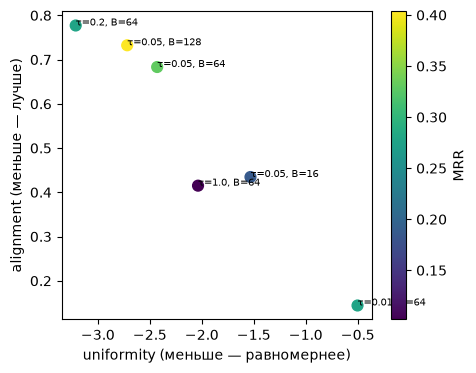

In [10]:
def align_uniform(m, n=1000):
    n = min(n, len(test))
    docs = test[:n]
    q_ids = pad_batch([encode(t) for _, t, _ in docs])
    d_ids = pad_batch([encode(d) for _, _, d in docs])
    with torch.no_grad():
        q = encode_norm(m, q_ids)
        d = encode_norm(m, d_ids)
        align = ((q - d) ** 2).sum(-1).mean().item()
        all_emb = torch.cat([q, d], dim=0)            # 2n
        if len(all_emb) <= 800:
            D2 = torch.cdist(all_emb, all_emb) ** 2
            off = ~torch.eye(len(all_emb), dtype=torch.bool, device=D2.device)
            unif = torch.log(torch.exp(-2 * D2[off]).mean()).item()
        else:                                          # сэмплируем пары
            n_pairs = 50_000
            i = torch.randint(0, len(all_emb), (n_pairs,))
            j = torch.randint(0, len(all_emb), (n_pairs,))
            keep = i != j
            D2 = ((all_emb[i] - all_emb[j]) ** 2).sum(-1)[keep]
            unif = torch.log(torch.exp(-2 * D2).mean()).item()
    return align, unif

AB_STEPS = 200 if FAST_DEV_RUN else 2000
configs = [(t, 64) for t in (0.01, 0.05, 0.2, 1.0)] + [(0.05, 16), (0.05, 128)]
rows = []
for tau, B in configs:
    m = train_biencoder(tau=tau, B=B, steps=AB_STEPS, use_hard=False)
    a, u = align_uniform(m); mrr = retrieval_metrics(embed_texts(m, q_texts) @ embed_texts(m, d_texts).T)["MRR"]
    rows.append({"tau": tau, "batch": B, "MRR": mrr, "align": a, "uniform": u})
au = pd.DataFrame(rows); display(au.round(3))
plt.figure(figsize=(5, 4)); sc = plt.scatter(au.uniform, au["align"], c=au.MRR, cmap="viridis", s=60)
for _, r in au.iterrows(): plt.annotate(f"τ={r.tau}, B={int(r.batch)}", (r.uniform, r["align"]), fontsize=7)
plt.colorbar(sc, label="MRR"); plt.xlabel("uniformity (меньше — равномернее)"); plt.ylabel("alignment (меньше — лучше)"); plt.show()

## 7. Cross-encoder и реранкинг

Cross-encoder получает `[CLS] заголовок [SEP] описание` и выдаёт скаляр релевантности (линейный слой над mean pooling; `[CLS]` при MLM-предобучении не обучался). Обучите его со списочной функцией потерь: для каждого запроса кандидаты — позитив, hard negative и 6 случайных документов, loss — кросс-энтропия softmax по кандидатам с позитивом на первом месте. Переранжируйте top-20 bi-encoder двумя способами:
1. только по оценке cross-encoder;
2. по смеси \(z(s_{bi}) + \lambda z(s_{ce})\), где \(z\) — нормировка оценок внутри top-20 каждого запроса, \(\lambda \in \{0.25, 0.5, 1\}\).

In [11]:
class CrossEncoder(nn.Module):
    def __init__(self, enc):
        super().__init__(); self.enc = copy.deepcopy(enc); self.score = nn.Linear(enc.emb.embedding_dim, 1)
    def forward(self, q_ids, d_ids):
        x = pad_batch([q + [SEP] + [t for t in d if t != CLS][:MAX_LEN] for q, d in zip(q_ids, d_ids)])
        h = self.enc(x); m = (x != PAD).float()[..., None]
        return self.score((h * m).sum(1) / m.sum(1)).squeeze(-1)

def train_cross(steps=200 if FAST_DEV_RUN else 3000, B=16, n_rand=6):
    set_seed(); ce = CrossEncoder(mlm).to(DEVICE); opt = torch.optim.AdamW(ce.parameters(), lr=3e-4)
    # (для каждого запроса 1 позитив + 1 hard negative + n_rand случайных; cross_entropy по кандидатам, метка 0)
    for s in range(steps):
        idx = random.sample(range(len(pairs)), B)
        q_batch, d_batch = [], []
        for i in idx:
            q = pairs[i][0]
            cand = [pairs[i][1],
                    pairs[hard_neg[i]][1]]
            cand += [pairs[random.randrange(len(pairs))][1] for _ in range(n_rand)]
            for c in cand:
                q_batch.append(q); d_batch.append(c)
        scores = ce(q_batch, d_batch).view(B, n_rand + 2)
        labels = torch.zeros(B, dtype=torch.long, device=DEVICE)
        loss = F.cross_entropy(scores, labels)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(ce.parameters(), 1.0); opt.step()

    return ce

@torch.no_grad()
def rerank(S, ce, k=20, lam=None):
    """lam=None — только cross-encoder; иначе z(bi) + lam * z(ce) внутри top-k. Документы вне top-k получают -inf."""
    ce.eval()
    n_q = S.shape[0]
    topk_vals, topk_idx = S.topk(k, dim=1)
    ce_scores = torch.zeros(n_q, k)
    for i in range(n_q):
        q_ids = [encode(q_texts[i])] * k
        d_ids = [encode(d_texts[j]) for j in topk_idx[i].tolist()]
        ce_scores[i] = ce(q_ids, d_ids).cpu()
    if lam is None:
        final = ce_scores
    else:
        zb = (topk_vals - topk_vals.mean(1, keepdim=True)) / (topk_vals.std(1, keepdim=True) + 1e-8)
        zc = (ce_scores - ce_scores.mean(1, keepdim=True)) / (ce_scores.std(1, keepdim=True) + 1e-8)
        final = zb + lam * zc
    S_new = torch.full_like(S, -float("inf"))
    S_new.scatter_(1, topk_idx, final)
    return S_new

t0 = time.time(); cross = train_cross(); print(f"cross-encoder: {time.time() - t0:.0f} c")
S_bi = embed_texts(bienc, q_texts) @ embed_texts(bienc, d_texts).T
res["+ cross-encoder (только CE)"] = retrieval_metrics(rerank(S_bi, cross))
for lam in (0.25, 0.5, 1.0): res[f"+ смесь bi + {lam}·CE"] = retrieval_metrics(rerank(S_bi, cross, lam=lam))
pd.DataFrame(res).T.round(3)

cross-encoder: 2 c


,Recall@1,Recall@5,Recall@10,MRR,nDCG@10
TF-IDF,0.634,0.775,0.808,0.697,0.721
MLM без дообучения,0.025,0.084,0.149,0.067,0.076
bi-encoder,0.289,0.480,0.553,0.381,0.414
+ cross-encoder (только CE),0.053,0.212,0.376,0.145,0.184
+ смесь bi + 0.25·CE,0.283,0.473,0.553,0.374,0.411
+ смесь bi + 0.5·CE,0.275,0.467,0.548,0.366,0.404
+ смесь bi + 1.0·CE,0.247,0.442,0.530,0.340,0.379


## 8. Минимальный RAG

Предобученная instruct-LLM классифицирует тему заголовка. Сравните четыре варианта контекста:
1. без контекста (zero-shot);
2. 4 случайных размеченных примера;
3. 4 ближайших по bi-encoder размеченных примера из обучающей выборки (retrieval);
4. 4 ближайших примера с **перепутанными** метками.

Ответ выбирается по максимуму логита первого токена названия класса после промпта (а не свободной генерацией), чтобы исключить ошибки формата; первые токены четырёх классов различаются. Используется базовая (не instruct) модель с обычным few-shot-промптом: в контрольных прогонах шаблон чата у маленьких instruct-моделей давал точность на уровне случайной. В `FAST_DEV_RUN` — SmolLM2-360M, в полном режиме — Qwen2.5-1.5B.

In [16]:
# ==== Загрузка предобученных моделей Hugging Face ====
from transformers import AutoTokenizer, AutoModelForCausalLM

def load_lm(name, dtype=None):
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    dtype = dtype or (torch.float16 if DEVICE == "cuda" else torch.float32)
    try:
        model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype)
    return model.to(DEVICE).eval(), tok

@torch.no_grad()
def perplexity(model, tok, text, max_len=512, stride=256, max_windows=None):
    ids = tok(text, return_tensors="pt").input_ids.to(DEVICE)
    nll, cnt, prev = 0.0, 0, 0
    for i, start in enumerate(range(0, ids.size(1) - 1, stride)):
        if max_windows and i >= max_windows: break
        end = min(start + max_len, ids.size(1)); x = ids[:, start:end]
        tgt = x.clone(); tgt[:, : max(0, prev - start)] = -100
        out = model(x, labels=tgt)
        n = (tgt[:, 1:] != -100).sum().item(); nll += out.loss.float().item() * n; cnt += n; prev = end
        if end == ids.size(1): break
    return math.exp(nll / cnt)

e:\temp\llm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
LLM_NAME = "HuggingFaceTB/SmolLM2-360M" if FAST_DEV_RUN else "Qwen/Qwen2.5-1.5B"
llm, llm_tok = load_lm(LLM_NAME)
N_RAG = 80 if FAST_DEV_RUN else 1000
kb = probe_train; kb_emb = embed_texts(bienc, [t for _, t, _ in kb])
CLASS_FIRST = [llm_tok(" " + c, add_special_tokens=False).input_ids[0] for c in CLASSES]
assert len(set(CLASS_FIRST)) == 4, "первые токены классов должны различаться"

def build_prompt(title, examples):
    shots = "".join(f"Headline: {t}\nTopic: {CLASSES[y]}\n\n" for y, t in examples)
    return "Classify the news headline into one of the topics: World, Sports, Business, Sci/Tech.\n\n" + shots + f"Headline: {title}\nTopic:"

@torch.no_grad()
def classify(prompt):
    ids = llm_tok(prompt, return_tensors="pt").input_ids.to(DEVICE)
    logits = llm(ids).logits[0, -1]                    # (VOCAB,)
    class_logits = torch.tensor([logits[t].item() for t in CLASS_FIRST])
    return int(class_logits.argmax().item())


n_rag = min(N_RAG, len(test))
test_sub = test[:n_rag]
y_true = [y for y, _, _ in test_sub]

# без контекста
acc_none = np.mean([classify(build_prompt(t, [])) == y
                    for y, t, _ in test_sub])

# 4 случайных размеченных примера
acc_rand = np.mean([classify(build_prompt(
                        t, [(yy, tt) for yy, tt, _ in random.sample(kb, 4)])) == y
                    for y, t, _ in test_sub])

# 4 ближайших по bi-encoder
q_emb = embed_texts(bienc, [t for _, t, _ in test_sub])
_, nn_idx = (q_emb @ kb_emb.T).topk(4, dim=1)
def _shots(i):
    return [(kb[j][0], kb[j][1]) for j in nn_idx[i].tolist()]
acc_ret = np.mean([classify(build_prompt(t, _shots(i))) == y
                   for i, (y, t, _) in enumerate(test_sub)])

# те же примеры, но с перемешанными метками
acc_shuf = 0
for i, (y, t, _) in enumerate(test_sub):
    shots = _shots(i)
    labels = [s[0] for s in shots]
    random.shuffle(labels)
    shots_shuf = [(labels[k], shots[k][1]) for k in range(len(shots))]
    acc_shuf += (classify(build_prompt(t, shots_shuf)) == y)
acc_shuf /= n_rag

pd.DataFrame({
    "нет контекста":         [acc_none],
    "4 случайных":           [acc_rand],
    "retrieval-4":           [acc_ret],
    "4 примера, метки перемешаны": [acc_shuf],
}).T.round(3)


e:\temp\llm\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Roma\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM2-360M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
e:\temp\llm\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses sy

,0
нет контекста,0.588
4 случайных,0.475
retrieval-4,0.688
"4 примера, метки перемешаны",0.712


## Вопросы

1. Докажите неравенство \(I(q; d) \ge \log K - \mathcal{L}_{InfoNCE}\) (набросок) и объясните, почему большой батч полезен.
2. Как температура влияет на градиенты по hard negatives? Почему слишком малая \(\tau\) вредна?
3. Почему MLM-модель даёт лучшие признаки для классификации, чем каузальная того же размера? Почему для каузальной модели важно, какой токен брать?
4. В чём компромисс bi-encoder и cross-encoder по качеству и стоимости? Почему реранкинг применяют только к top-k?
5. По результатам п. 8: когда извлечённый контекст помогает, а когда мешает? Что показывает эксперимент с перепутанными метками о механизме in-context learning у вашей модели?

Вывод: обучили две маленькие языковые модели с маскированием и обычную каузальную и сравнили их на классификации новостей. MLM оказалась лучше каузальной, но хуже TF-IDF. Потом обучили bi-encoder искать описание по заголовку с помощью InfoNCE и проверили, как на качество поиска влияют температура и размер батча. Добавили cross-encoder для переранжирования найденных документов, но он не улучшил результаты. В конце собрали простой RAG, большая готовая LLM угадывала тему заголовка без примеров, со случайными примерами, с найденными примерами и с примерами с перепутанными метками. Оказалось, что найденные примеры помогают, но модель часто смотрит больше на формат примеров, чем на правильность их меток.